# 4. Solving the small systems: Cholesky and conditioning

*Part 4 of a series on non-negative least squares (NNLS). Previous:
[3. The active-set method](03_active_set_lawson_hanson.ipynb). Next:
[5. Many small fits, fast](05_many_small_fits_fast.ipynb).*

Both NNLS algorithms so far come down to the same small job, done many times: solve

$$G_{PP}\, z = c_P$$

for some support $P$, where $G = R^\top R$ and $c = R^\top s$. Notebook 2 handed that job to
`np.linalg.solve` and moved on. This notebook opens it up, because two things about it matter
for MrFitty's fast solver:

1. **How to solve it.** $G_{PP}$ is symmetric, and better, *positive definite*, and there's a
   method made for exactly that: the **Cholesky factorization**, which we'll derive entry by
   entry.
2. **How accurately.** Computers round. Usually that costs nothing you'd notice, but when two
   references are nearly identical, it can cost a lot, and forming $G = R^\top R$ makes it
   worse: it *squares* the damage. We'll measure it, prove it, and see what MrFitty does about
   it: one cheap check per fit that vouches for every support at once.

It starts with a few minutes on floating point. Theorems continue from notebook 3, which ended
at Theorem 15.

One change of letters: notebooks 2 and 3 used $\lambda$ for the slopes $\nabla f(w)$. This
notebook needs eigenvalues, which are usually called $\lambda$ too, so here eigenvalues are
$\mu$.

In [1]:
%matplotlib inline
import numpy as np

from nnls_tutorial import numerics as N
from nnls_tutorial import plotting as P
from nnls_tutorial.conditioning import (
    EPS,
    cond,
    cond_columns,
    digits_lost_experiment,
    stretch_factors,
    trace_bound,
)
from nnls_tutorial.data import load_arsenic
from nnls_tutorial.solvers import (
    back_substitution,
    cholesky,
    forward_substitution,
    lstsq_normal,
    lstsq_qr,
    solve_cholesky,
)

P.use_style()
np.set_printoptions(precision=4)

spectra = load_arsenic()
twins = [spectra.names.index(name) for name in N.TWINS]

## 1. Floating point in a few minutes

A computer stores a real number as a `float64`: a sign, 53 binary digits of mantissa, and an
exponent. That's about **16 significant decimal digits**, whatever the size of the number. Most
numbers, even simple ones like $0.1$, can't be stored exactly, so they're rounded to the
nearest float, and so is the result of every arithmetic operation.

The size of that rounding is measured by **machine epsilon**, the gap between 1 and the next
float up:

In [2]:
print("eps         =", EPS)
print("0.1 + 0.2   =", 0.1 + 0.2)
print("(1 + 1e-16) - 1 =", (1 + 1e-16) - 1)
print("(1 + 3e-16) - 1 =", (1 + 3e-16) - 1)

eps         = 2.220446049250313e-16
0.1 + 0.2   = 0.30000000000000004
(1 + 1e-16) - 1 = 0.0
(1 + 3e-16) - 1 = 2.220446049250313e-16


Every operation is exact up to a relative error of at most $\varepsilon/2 \approx 10^{-16}$.
One rounding is harmless. The trouble is that errors can be **amplified** by what comes after.
The cleanest example is subtracting two nearly equal numbers: if $x$ and $y$ agree in their
first 10 digits, $x - y$ has only about 6 correct digits left, because the agreeing digits
cancel and the rounding errors don't. Notebook 2 met this in its error shortcut, where
$s^\top s - z^\top c_P$ lost a couple of digits.

So the useful question about a computation isn't "is it exact?" (it never is) but "**how much
can it amplify small errors?**" That's what a condition number measures, and the answer is
usually phrased in digits: an amplification of $10^k$ costs about $k$ of the 16.

## 2. How much can a matrix amplify errors?

### Stretching

Think of $R$ as a machine that takes weights $w$ and makes a spectrum $Rw$. Feed it every
weight vector of length 1, and see how long the outputs are. The longest and shortest output
lengths,

$$\sigma_{\max} = \max_{\|w\| = 1} \|Rw\|, \qquad \sigma_{\min} = \min_{\|w\| = 1} \|Rw\|,$$

are $R$'s **stretch factors**. (Their official name is the largest and smallest *singular
values* of $R$.) The columns are independent exactly when $\sigma_{\min} > 0$: nothing but
$w = 0$ is squashed to zero. The **condition number** of $R$ is their ratio,

$$\kappa(R) = \frac{\sigma_{\max}}{\sigma_{\min}} \ge 1.$$

With two columns in the plane, you can see it: the unit circle of weights goes to an ellipse,
and the stretch factors are its half-axes. Two columns at right angles give a circle and
$\kappa(R) = 1$. As the angle between them closes, the ellipse flattens and $\kappa(R)$ blows
up.

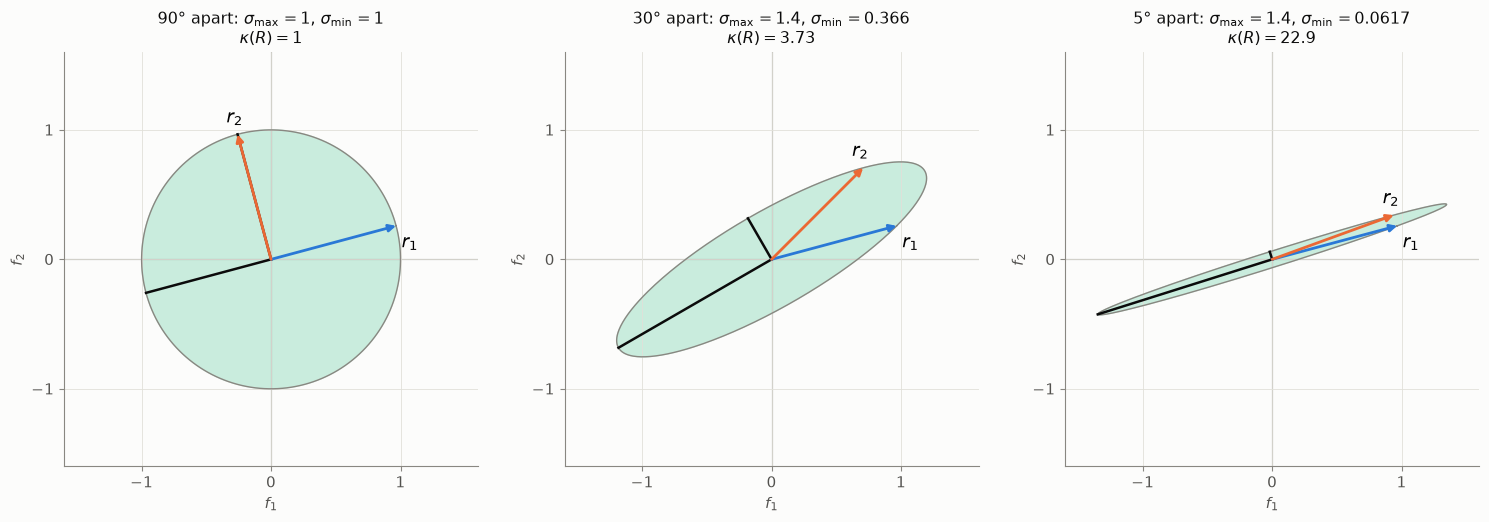

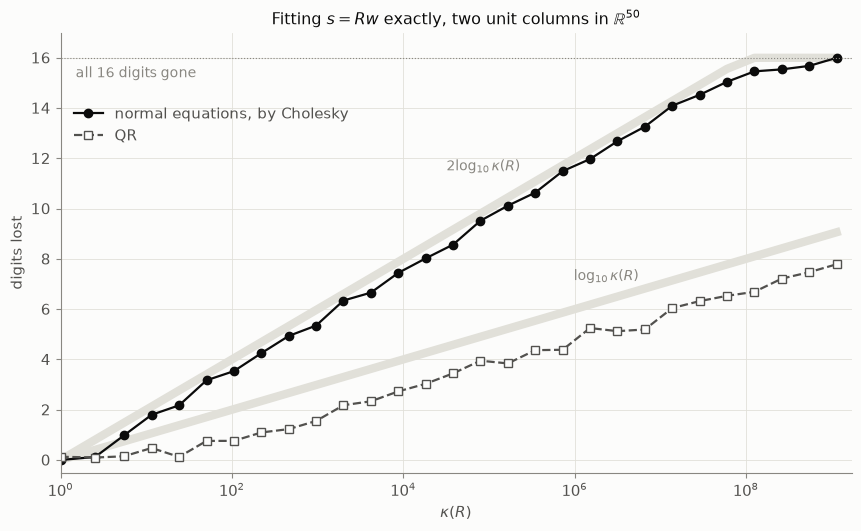

In [3]:
N.stretch_static()

**Figure 4.1.** Top: where $R$ sends the unit circle of weights, for two unit columns at
$90°$, $30°$ and $5°$ apart. The black segments are the ellipse's long and short half-axes, of
lengths $\sigma_{\max}$ and $\sigma_{\min}$. Bottom: how many digits a least-squares fit loses
to rounding, against $\kappa(R)$, for two unit columns at angles from $90°$ down to $10^{-7}$
degrees. Each fit is of an $s$ that the columns fit *exactly*, $s = Rw$, so the right answer
is known. The two methods are explained in Section 4. The gray bands are the rules of thumb
from Theorems 17 and 18: $2\log_{10}\kappa(R)$ and $\log_{10}\kappa(R)$.

Here's the same picture with a slider for the angle. Try the smallest angles: by
$10^{-6}$ degrees the normal equations lose all 16 digits, while QR still keeps about 9.

In [4]:
N.stretch_widget()

interactive(children=(FloatLogSlider(value=5.0, continuous_update=False, description='angle between $r_1$ and …

Why is "nearly flat" bad? A flat ellipse means some weight vectors $w$ of length 1 produce
almost nothing: $\|Rw\| = \sigma_{\min}$, tiny. Run that backwards. A tiny change in the
spectrum, a rounding error, say, can be explained by a *large* change in the weights. Fitting
undoes $R$, so it divides by $\sigma_{\min}$, and that's where errors get amplified.

### Eigenvalues, stated

To make that precise for $G = R^\top R$ we need one fact about symmetric matrices. It's
usually proved in a second linear algebra course, so here it's only stated.

> **The spectral theorem.** A symmetric $m \times m$ matrix $G$ has $m$ real eigenvalues
> $\mu_1 \le \dots \le \mu_m$, with eigenvectors $v_1, \dots, v_m$ that form an orthonormal
> basis of $\mathbb{R}^m$. The trace of $G$ is the sum of its eigenvalues.

From it, a fact we'll lean on all through this notebook: an eigenvector basis turns $G$ into
separate stretches along perpendicular axes.

> **Theorem 16 (Rayleigh's bounds).** Let $G$ be symmetric with eigenvalues
> $\mu_{\min} = \mu_1 \le \dots \le \mu_m = \mu_{\max}$. For every vector $w$,
> $$\mu_{\min}\|w\|^2 \;\le\; w^\top G w \;\le\; \mu_{\max}\|w\|^2,$$
> with equality on the left at $w = v_1$ and on the right at $w = v_m$. If every eigenvalue
> is positive, then also $\mu_{\min}\|w\| \le \|Gw\| \le \mu_{\max}\|w\|$.

*Proof.* Write $w = \sum_i a_i v_i$. Since $G v_i = \mu_i v_i$ and the $v_i$ are orthonormal,
$w^\top G w = \sum_i \mu_i a_i^2$ and $\|w\|^2 = \sum_i a_i^2$. Each $\mu_i$ is between
$\mu_{\min}$ and $\mu_{\max}$, which gives the first pair of inequalities, and putting all of
$w$ on $v_1$ or on $v_m$ gives the equality cases. Similarly
$\|Gw\|^2 = \sum_i \mu_i^2 a_i^2$, and when every $\mu_i > 0$, each $\mu_i^2$ is between
$\mu_{\min}^2$ and $\mu_{\max}^2$. $\blacksquare$

A symmetric $G$ is **positive definite** if $w^\top G w > 0$ for every $w \ne 0$, which by
Theorem 16 means every eigenvalue is positive. Our $G = R^\top R$ is positive definite when
the columns are independent, since $w^\top G w = \|Rw\|^2 > 0$ for $w \ne 0$. For such a $G$,
define $\kappa(G) = \mu_{\max} / \mu_{\min}$.

### What the condition number promises

> **Theorem 17 (errors are amplified by at most $\kappa$).** Let $G$ be positive definite,
> $Gz = c$ with $c \ne 0$, and $G(z + \delta z) = c + \delta c$. Then
> $$\frac{\|\delta z\|}{\|z\|} \;\le\; \kappa(G)\,\frac{\|\delta c\|}{\|c\|}.$$

*Proof.* Subtracting, $G\,\delta z = \delta c$. By Theorem 16,
$\mu_{\min}\|\delta z\| \le \|G\,\delta z\| = \|\delta c\|$ and
$\|c\| = \|Gz\| \le \mu_{\max}\|z\|$. Divide the first by the second. $\blacksquare$

In words: a relative error in the data can come out of the solve up to $\kappa(G)$ times
bigger. Rounding errors are relative errors of about $10^{-16}$, so solving a system with
$\kappa(G) = 10^k$ can lose about $k$ digits. (Errors in $G$ itself obey a similar bound, to
first order.) And the bound is attained, when $\delta c$ points along $v_1$ and $c$ along
$v_m$, so it's not just pessimism.

### The catch: forming $R^\top R$ squares it

> **Theorem 18 (the normal equations square the condition number).** If $R$ has independent
> columns and $G = R^\top R$, then the eigenvalues of $G$ are the squares of $R$'s stretch
> factors, $\mu_{\max} = \sigma_{\max}^2$ and $\mu_{\min} = \sigma_{\min}^2$, so
> $$\kappa(G) = \kappa(R)^2.$$

*Proof.* For any $w$, $\|Rw\|^2 = w^\top R^\top R\, w = w^\top G w$. Over unit vectors $w$,
Theorem 16 says the largest and smallest values of the right side are $\mu_{\max}$ and
$\mu_{\min}$. The largest and smallest values of the left side are $\sigma_{\max}^2$ and
$\sigma_{\min}^2$, by definition. $\blacksquare$

That's bad news for both notebook 2 and notebook 3, which solve $G_{PP}\,z = c_P$. The fit
itself, recovering $w$ from $s$, has condition number $\kappa(R)$: that much loss is the
problem's fault, and any method suffers it. But by going through $G$, those methods face
$\kappa(R)^2$, twice as many digits lost. That's the steep line in Figure 4.1.

## 3. The twins

Is this a real concern for XANES? Two of the bundled references, As$_2$O$_3$ and sodium
arsenite, are both arsenic(III) bound to oxygen, and their spectra are almost
indistinguishable:

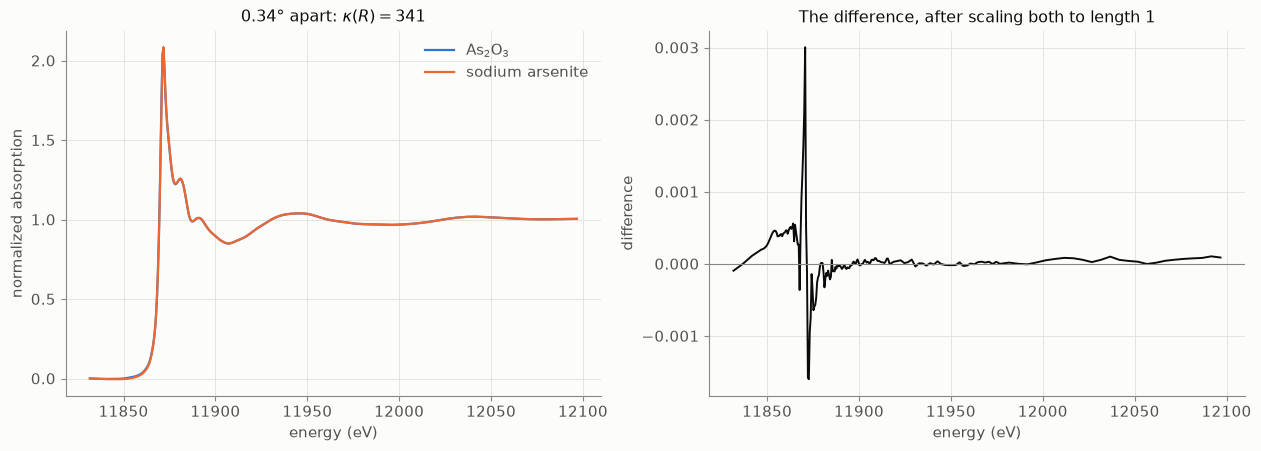

In [5]:
P.show(N.twins_figure(spectra))

**Figure 4.2.** The two most nearly identical references in the bundled pool. Left: the
spectra, on top of each other. Right: their difference after scaling each to length 1, at
most about 0.003, around the absorption edge.

As vectors in $\mathbb{R}^{198}$, they're only $0.34°$ apart. Exercise 1 shows that two unit
vectors at an angle $\theta$ have $\kappa(R) = \cot(\theta/2)$, which here is about 337. The
real value is close:

In [6]:
R_twins = spectra.R[:, twins]
sigma_min, sigma_max = stretch_factors(R_twins)
print(f"stretch factors: {sigma_min:.4f} and {sigma_max:.2f}")
print(f"kappa(R)   = {cond_columns(R_twins):.1f}")
print(f"kappa(R)^2 = {cond_columns(R_twins) ** 2:.4g}")
print(f"kappa(G)   = {cond(R_twins.T @ R_twins):.4g}")

stretch factors: 0.0545 and 18.61
kappa(R)   = 341.3
kappa(R)^2 = 1.165e+05
kappa(G)   = 1.165e+05


As Theorem 18 says, $\kappa(G) = \kappa(R)^2 \approx 1.2 \times 10^5$. A solve through $G$ can
lose about 5 digits, against about 2.5 for a method that works on $R$ directly. Here's the
experiment from Figure 4.1, now with the twins as the columns:

In [7]:
lost_normal, lost_qr = digits_lost_experiment(R_twins)
print(f"digits lost: normal equations {lost_normal:.1f}, QR {lost_qr:.1f}")

digits lost: normal equations 4.4, QR 1.3


And here's the unconstrained fit of the measured spectrum using only the twins:

In [8]:
print("normal equations:", lstsq_normal(R_twins, spectra.s))
print("QR:              ", lstsq_qr(R_twins, spectra.s))

normal equations: [ 23.9291 -22.9208]
QR:               [ 23.9291 -22.9208]


Look at those weights: 24 of one, minus 23 of the other. That's what a flat ellipse looks like
in practice. The fit wants "a little arsenic(III)", and because the two spectra are nearly the
same, a huge positive amount of one and a huge negative amount of the other cancel almost
perfectly into the small difference the fit needs. NNLS can't do that (no negative weights),
which is one of its virtues here. The two methods agree to about 12 digits, which is plenty:
4 digits lost out of 16 leaves a lot. But the twins are only $0.34°$ apart. MrFitty's
notebook found pairs of scans at a correlation distance of 0.0002 in other reference pools,
and the cost grows fast as the angle closes.

## 4. Two ways to solve least squares

### The normal equations, by Cholesky

This is what notebooks 2 and 3 do: form $G = R^\top R$ and $c = R^\top s$, then solve
$Gw = c$. Since $G$ is symmetric and positive definite, the best way to solve it is to factor

$$G = L L^\top,$$

with $L$ **lower triangular** (zeros above the diagonal) and positive on its diagonal. Then
$Gw = c$ is two easy triangular systems: $Ly = c$, solved from the top row down (each row has
one new unknown), then $L^\top w = y$, solved from the bottom row up.

Where does $L$ come from? Just multiply out $LL^\top$ and match entries. For $2 \times 2$:

$$
\begin{pmatrix} G_{11} & G_{12} \\ G_{21} & G_{22} \end{pmatrix}
= \begin{pmatrix} L_{11} & 0 \\ L_{21} & L_{22} \end{pmatrix}
  \begin{pmatrix} L_{11} & L_{21} \\ 0 & L_{22} \end{pmatrix}
= \begin{pmatrix} L_{11}^2 & L_{11}L_{21} \\ L_{11}L_{21} & L_{21}^2 + L_{22}^2 \end{pmatrix}.
$$

Read off $L_{11} = \sqrt{G_{11}}$, then $L_{21} = G_{21}/L_{11}$, then
$L_{22} = \sqrt{G_{22} - L_{21}^2}$. Each entry needs only entries already found. The same
matching for any size gives, column by column, for $j = 1, \dots, m$:

$$
L_{jj} = \sqrt{G_{jj} - \sum_{k < j} L_{jk}^2},
\qquad
L_{ij} = \frac{1}{L_{jj}}\Big(G_{ij} - \sum_{k<j} L_{ik}L_{jk}\Big) \quad (i > j).
$$

Figure 4.3 shows the order the entries are filled in, and what each one reads.

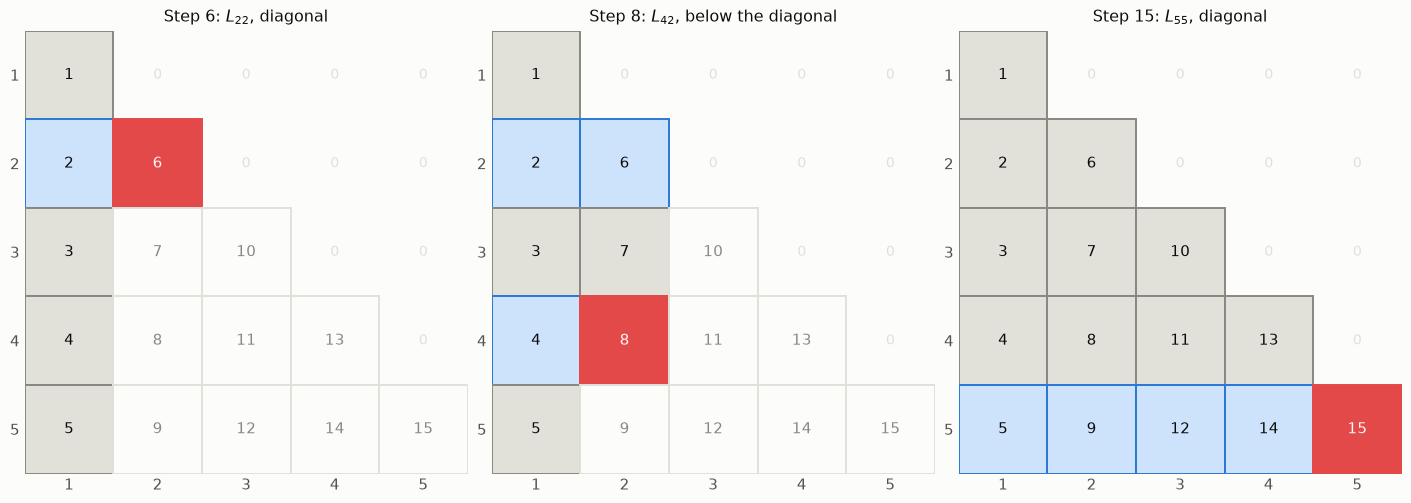

In [9]:
N.cholesky_static()

**Figure 4.3.** Factoring a $5 \times 5$ matrix. The numbers give the order in which the
entries of $L$ are computed: down the first column, then down the second, and so on. Red is
the entry being computed, blue the entries of $L$ it reads (plus $G$'s entry in the same
place), and gray the entries already done. Left: the diagonal entry $L_{22}$ reads the row to
its left. Middle: $L_{42}$, below the diagonal, reads the start of its own row and of row 2,
and divides by $L_{22}$. Right: the last entry reads all of row 5. Each entry only reads
entries with smaller numbers, so the order works.

In [10]:
N.cholesky_widget()

interactive(children=(IntSlider(value=1, continuous_update=False, description='step', max=15, min=1, style=Sli…

The only thing that could go wrong is a square root of a negative number, or a zero on the
diagonal to divide by. For positive-definite $G$, it can't:

> **Theorem 19 (Cholesky works).** If $G$ is symmetric and positive definite, every number
> under a square root in the formulas above is positive. So $G = LL^\top$ for a lower-triangular
> $L$ with positive diagonal.

*Proof.* By induction on $m$; $m = 1$ is $L_{11} = \sqrt{G_{11}}$, and $G_{11} > 0$. In general,
split off the first row and column, $G = \begin{pmatrix} a & b^\top \\ b & C\end{pmatrix}$.
Here $a = G_{11} > 0$, because $a = e_1^\top G e_1$. The first column of $L$ is $\sqrt a$ and
then $b/\sqrt a$, and matching entries, the rest of $L$ must satisfy $L' L'^\top = S$, where

$$S = C - \frac{b\,b^\top}{a}.$$

(Subtracting the first column's contribution from $C$ is exactly what the sums in the formulas
do.) $S$ is positive definite: for $v \ne 0$, take $w = \big({-b^\top v}/{a},\; v\big) \ne 0$.
Multiplying out,

$$0 < w^\top G w = a\Big(\frac{b^\top v}{a}\Big)^2 - 2\,\frac{(b^\top v)^2}{a} + v^\top C v
  = v^\top S v.$$

So by induction $S = L'L'^\top$ with positive diagonal, and that finishes $L$. $\blacksquare$

Cholesky takes about $m^3/6$ multiplications, half of what general Gaussian elimination
needs, because the symmetry means only half of $G$ has to be worked through. It also needs no
pivoting, row swaps for safety, which general elimination does. For MrFitty's systems,
$m \le 5$, so it's a few dozen operations. Here's the package's version, checked against NumPy:

In [11]:
G_full = spectra.R.T @ spectra.R
c_full = spectra.R.T @ spectra.s
L = cholesky(G_full)
print("largest difference from np.linalg.cholesky:", np.abs(L - np.linalg.cholesky(G_full)).max())
y = forward_substitution(L, c_full)
w = back_substitution(L.T, y)
print("solve_cholesky matches:", np.allclose(w, solve_cholesky(G_full, c_full)))
print("largest difference from np.linalg.solve:", np.abs(w - np.linalg.solve(G_full, c_full)).max())

largest difference from np.linalg.cholesky: 9.250933352689117e-14
solve_cholesky matches: True
largest difference from np.linalg.solve: 2.0999868510784836e-12


### QR: never forming $R^\top R$

The other way, the one Figure 4.1 calls QR, avoids $G$ altogether. It factors $R$ itself,

$$R = QU,$$

where $Q$ is $n \times m$ with orthonormal columns ($Q^\top Q = I$) and $U$ is $m \times m$ upper
triangular. (This is usually written $QR$, but we already have an $R$.) It's Gram–Schmidt,
organized: the columns of $Q$ are an orthonormal basis for the span of the columns of $R$, and
$U$ records how to rebuild each column of $R$ from them. Substituting into the normal equations,
$U^\top Q^\top Q U w = U^\top Q^\top s$, so $U^\top U w = U^\top Q^\top s$, and since $U$ is
invertible,

$$U w = Q^\top s,$$

one triangular system. Here's why that helps:

> **Theorem 20 (QR doesn't square).** If $R = QU$ with $Q^\top Q = I$, then $U$ has the same
> stretch factors as $R$, so $\kappa(U) = \kappa(R)$.

*Proof.* $\|Rw\|^2 = \|QUw\|^2 = (Uw)^\top Q^\top Q\,(Uw) = \|Uw\|^2$ for every $w$: $Q$ doesn't
change lengths. $\blacksquare$

So QR faces $\kappa(R)$, not $\kappa(R)^2$, which is the lower curve in Figure 4.1. (One honest
footnote: when the fit isn't close to exact, even QR's error picks up a $\kappa(R)^2$ term,
multiplied by the size of the residual. For good fits, that term is small.) Lawson and
Hanson's NNLS works this way, through QR factorizations of $R$'s columns, and SciPy's solver
follows their original code, which is why it's the safe one when references are nearly
identical.

Then why does MrFitty use the normal equations at all? Because of notebook 2's squeeze: once $G$
and $c$ are formed, every support's system is a tiny $|P| \times |P|$ problem, and no vector
of length 198 is touched again. With millions of fits, that's a big saving. The price is the
squared condition number, and the next section is about how MrFitty keeps that price under
control.

## 5. One check for every support

Using the normal equations safely means checking $\kappa(G_{PP})$ before trusting the solve.
But there are $2^m - 1$ supports. Checking each one would cost more than solving it. Luckily,
one check is enough:

> **Theorem 21 (removing columns doesn't make it worse).** If $G$ is positive definite and
> $G_{PP}$ is the submatrix for the rows and columns in $P$, then
> $$\mu_{\min}(G) \le \mu_{\min}(G_{PP}) \quad\text{and}\quad \mu_{\max}(G_{PP}) \le \mu_{\max}(G),
> \qquad\text{so}\qquad \kappa(G_{PP}) \le \kappa(G).$$

*Proof.* For a vector $u \in \mathbb{R}^{|P|}$, let $w$ be $u$ padded with zeros outside $P$.
Then $w^\top G w = u^\top G_{PP}\, u$ and $\|w\| = \|u\|$. So the values of
$u^\top G_{PP} u / \|u\|^2$ are some of the values of $w^\top G w / \|w\|^2$, and by Theorem 16,
the extreme values of each are the extreme eigenvalues. A smaller set of values has a larger
(or equal) minimum and a smaller (or equal) maximum. $\blacksquare$

In terms of the references: dropping columns from $R$ can't make the remaining ones more nearly
dependent. (This is the extreme case of *Cauchy's interlacing theorem*, which says more about
the eigenvalues in between, but the extremes are all we need.) Here's every one of the 1023
supports of the ten bundled references:

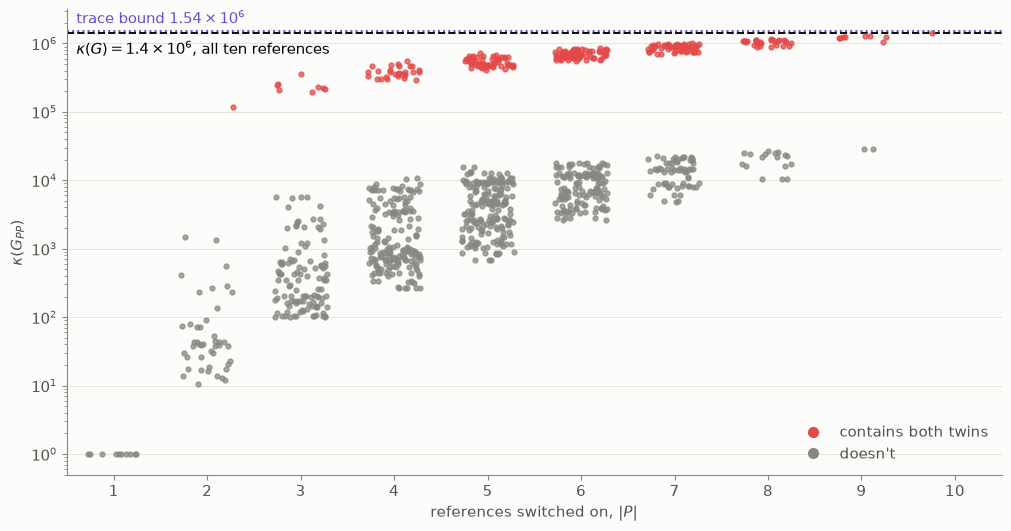

In [12]:
P.show(N.support_conditioning_figure(spectra))

**Figure 4.4.** The condition number of $G_{PP}$ for every support $P$ of the ten references,
grouped by size, with small random sideways shifts so the dots don't overlap. Red supports
contain both twins. Every dot is below the dashed line, $\kappa(G)$ for all ten references
(Theorem 21). The dotted line is the trace bound of Theorem 22. The twins dominate: any support
with both of them is at least $10^5$, and any support without them is at most about
$3 \times 10^4$.

So MrFitty checks $\kappa(G)$ once per fit, for the combination's full $G$, and if it's below
a limit ($10^8$, which leaves at least 8 digits), every support's solve is trusted. Fits above
the limit go to SciPy's solver instead, which works on $R$ directly.

### A check without eigenvalues

One more wrinkle. Computing eigenvalues is a job for a library routine (LAPACK, through
`np.linalg.eigvalsh`), and MrFitty's notebook found that calling it from many threads at once
took 98% of the compiled solver's time. So the compiled solver uses a bound instead, built from
things it has anyway:

> **Theorem 22 (the trace bound).** If $G$ is $m \times m$ and positive definite, then
> $$\kappa(G) \;\le\; \operatorname{tr}(G)\,\operatorname{tr}(G^{-1}) \;\le\; m^2\,\kappa(G).$$
> And if $G = LL^\top$, then $\operatorname{tr}(G^{-1})$ is the sum of the squares of the entries
> of $L^{-1}$.

*Proof.* The eigenvalues are positive and the trace is their sum, so
$\mu_{\max} \le \operatorname{tr}(G) \le m\,\mu_{\max}$. The eigenvalues of $G^{-1}$ are the
$1/\mu_i$ (same eigenvectors), and the largest of them is $1/\mu_{\min}$, so
$1/\mu_{\min} \le \operatorname{tr}(G^{-1}) \le m/\mu_{\min}$. Multiply the two.

For the second part, $G^{-1} = (LL^\top)^{-1} = (L^{-1})^\top L^{-1}$. For any matrix $B$, the
diagonal entries of $B^\top B$ are the squared lengths of $B$'s columns, so
$\operatorname{tr}(B^\top B)$ is the sum of the squares of all of $B$'s entries. Take
$B = L^{-1}$. $\blacksquare$

$L^{-1}$ costs only triangular solves, one per column of the identity, and the compiled solver
has $L$ already. The bound can overestimate by up to $m^2$, so it might send a borderline fit to
SciPy unnecessarily, but it never lets a badly conditioned one through. On the bundled
references it's tight:

In [13]:
print(f"kappa(G) for all ten references = {cond(G_full):.4g}")
print(f"trace bound                     = {trace_bound(G_full):.4g}")
print(f"tr(G) tr(G^-1), the long way    = {np.trace(G_full) * np.trace(np.linalg.inv(G_full)):.4g}")
print(f"m^2 kappa(G)                    = {len(G_full) ** 2 * cond(G_full):.4g}")

kappa(G) for all ten references = 1.404e+06
trace bound                     = 1.544e+06
tr(G) tr(G^-1), the long way    = 1.544e+06
m^2 kappa(G)                    = 1.404e+08


Only 10% over. That's typical when one eigenvalue is much smaller than the others, as with a
pair of twins: $\operatorname{tr}(G^{-1})$ is then almost all $1/\mu_{\min}$. The bound is
loosest, a full factor of $m^2$, when every eigenvalue is the same (Exercise 3).

## Exercises

**1.** *Two unit columns.* Let $r_1, r_2$ be unit vectors at an angle $\theta$, with
$0 < \theta \le 90°$. Find the eigenvalues of $G = R^\top R$, and show that
$\kappa(G) = \cot^2(\theta/2)$ and $\kappa(R) = \cot(\theta/2)$. Check it against the twins at
$\theta = 0.34°$, and against the titles in Figure 4.1.

<details><summary>Solution</summary>

$G = \begin{pmatrix} 1 & \cos\theta \\ \cos\theta & 1\end{pmatrix}$, with eigenvectors
$(1, 1)$ and $(1, -1)$ and eigenvalues $1 + \cos\theta$ and $1 - \cos\theta$. So
$\kappa(G) = \frac{1 + \cos\theta}{1 - \cos\theta} = \frac{2\cos^2(\theta/2)}{2\sin^2(\theta/2)}
= \cot^2(\theta/2)$, and $\kappa(R) = \sqrt{\kappa(G)} = \cot(\theta/2)$ by Theorem 18. The
stretch factors are $\sqrt{1 \pm \cos\theta}$: at $30°$, $1.37$ and $0.366$, giving
$\kappa(R) = 3.73$. For the twins, $\cot(0.17°) \approx 337$, against the true 341. The twins
aren't the same length, which accounts for the difference.
</details>

**2.** *Cholesky for every leading block at once.* Show that if $G = LL^\top$, then for each
$k$, the top-left $k \times k$ block of $L$ is the Cholesky factor of the top-left $k \times k$
block of $G$. Which supports could reuse one factorization this way, and why can't all of them?

<details><summary>Solution</summary>

Look at the formulas: the entries $L_{ij}$ with $i, j \le k$ use only $G_{ij}$ with
$i, j \le k$ and other entries of $L$ in the top-left block. So computing the factor of the
$k \times k$ block runs exactly the same steps and gets the same numbers. (Or: write $L$ in
blocks; the top-left block of $LL^\top$ is $L_{11}L_{11}^\top$, because the block of $L$ above
the diagonal is zero.) Supports of the form $\{1, \dots, k\}$, prefixes, can reuse one
factorization. A support like $\{2, 3\}$ isn't a leading block in this order, so it needs its
own, unless the references are reordered, and no single order makes every support a prefix.
</details>

**3.** *How tight is the trace bound?* Show that the trace bound equals $m^2\kappa(G)$ exactly
when $G = I$, and that for $G = \operatorname{diag}(1, \delta)$ with small $\delta > 0$ it is
about $\kappa(G)$. What does that say about when MrFitty's check is pessimistic?

<details><summary>Solution</summary>

For $G = I$: $\kappa = 1$ and $\operatorname{tr}(G)\operatorname{tr}(G^{-1}) = m \cdot m = m^2$.
For $\operatorname{diag}(1, \delta)$: $\kappa = 1/\delta$ and the bound is
$(1 + \delta)(1 + 1/\delta) = 1/\delta + 2 + \delta \approx \kappa$. The bound is pessimistic
when the eigenvalues are spread evenly, which is when $G$ is well conditioned, so the check
is far from its limit anyway. When $G$ is badly conditioned because of one nearly dependent
direction, as with the twins, the bound is nearly exact, which is when it matters.
</details>

**4.** *Break Cholesky.* Make $R$ with an exact duplicate column, and run `cholesky` on
$G = R^\top R$. What goes wrong, and at which entry? What would MrFitty's check have done with
this $G$?

In [14]:
rng = np.random.default_rng(4)
R_dup = rng.random((30, 3))
R_dup = np.column_stack([R_dup, R_dup[:, 1]])  # r_4 is a copy of r_2

<details><summary>Solution</summary>

```python
with np.errstate(all="ignore"):
    print(cholesky(R_dup.T @ R_dup))
```

The first three columns factor fine, and row 4 comes out as a copy of row 2. At $L_{44}$ the
number under the square root is $G_{44} - \sum_{k<4} L_{4k}^2$, which is zero in exact
arithmetic: $r_4$ adds nothing new, so nothing is left over. Here it happens to come out as
exactly 0 in floating point too, so $L_{44} = 0$ and the factorization finishes, quietly.
The damage comes in the solve, which divides by $L_{44}$ and returns `inf` or `nan`. With
other numbers, rounding leaves something like $\pm 10^{-15}$ instead: negative gives a `nan`
square root, and tiny positive gives a tiny $L_{44}$ and a huge, meaningless answer. Either
way, no error is raised. $G$ is singular, so $\kappa(G)$ is infinite. In floating point, the
smallest eigenvalue comes out as a rounding error, possibly negative, so MrFitty's check fails
and the fit goes to SciPy.
Theorem 11 says the supports containing both copies are never needed, and SciPy's solver
never builds one (Theorem 13).
</details>

## Summary

- A `float64` carries about 16 digits, and every operation rounds. What matters is how much
  later steps **amplify** those errors, and the **condition number** measures it: about
  $\log_{10}\kappa$ digits lost (Theorem 17).
- $\kappa(R)$ is the ratio of $R$'s largest and smallest **stretch factors**: how flat the
  ellipse $\{Rw : \|w\| = 1\}$ is. Nearly identical references make it very flat.
- **Forming $G = R^\top R$ squares it**: $\kappa(G) = \kappa(R)^2$ (Theorem 18). QR works on
  $R$ directly and doesn't (Theorem 20).
- **Cholesky**, $G = LL^\top$, is derived by matching entries, works for every positive-definite
  $G$ (Theorem 19), and turns each solve into two triangular ones.
- **One check covers every support**: $\kappa(G_{PP}) \le \kappa(G)$ (Theorem 21), and the trace
  bound $\operatorname{tr}(G)\operatorname{tr}(G^{-1}) = \operatorname{tr}(G)\,\|L^{-1}\|_F^2$
  checks it without eigenvalues (Theorem 22).
- The real twins, As$_2$O$_3$ and sodium arsenite, are $0.34°$ apart, with
  $\kappa(G) \approx 1.2 \times 10^5$: about 4 digits lost through the normal equations
  against about 1 through QR, comfortably inside MrFitty's limit.

**Next:** [notebook 5](05_many_small_fits_fast.ipynb) puts the pieces together into MrFitty's fast
solver: every support, every fit, Cholesky written out by hand, batched in NumPy and then compiled
with Numba.